# Clasificacion de imagenes con Fashion-MNIST
## Notebook base en PyTorch

Este notebook introduce el flujo completo de un proyecto de vision por
computadora con una CNN en PyTorch. Usaremos el dataset Fashion-MNIST,
que reemplaza los digitos escritos a mano de MNIST por 10 categorias de
prendas de vestir.

## Que es Fashion-MNIST

Fashion-MNIST fue creado por Zalando Research como un reemplazo directo
de MNIST. Sus caracteristicas son:

- 70.000 imagenes en escala de grises.
- 60.000 para entrenamiento y 10.000 para test.
- Tamano de 28x28 pixeles.
- 10 clases de prendas de vestir.
- Mismo formato que MNIST, por lo que el pipeline es casi identico.

Las 10 clases son:

| Indice | Clase |
|---|---|
| 0 | T-shirt/top |
| 1 | Trouser |
| 2 | Pullover |
| 3 | Dress |
| 4 | Coat |
| 5 | Sandal |
| 6 | Shirt |
| 7 | Sneaker |
| 8 | Bag |
| 9 | Ankle boot |

## Por que es util

- Es mas desafiante que MNIST porque las diferencias entre clases son
  mas sutiles (por ejemplo, shirt vs. pullover vs. coat).
- Mantiene la simplicidad del formato, lo que permite enfocarse en la
  arquitectura y el entrenamiento.
- Es un excelente punto intermedio antes de saltar a CIFAR-10.

## Objetivos del notebook

Al finalizar, seras capaz de:

1. Cargar y explorar un dataset de imagenes con torchvision.
2. Aplicar transformaciones y normalizacion.
3. Definir una CNN en PyTorch.
4. Entrenar con validacion y early stopping.
5. Evaluar con metricas robustas.
6. Visualizar filtros y feature maps.
7. Analizar errores del modelo.

## Configuracion inicial

Importamos las librerias necesarias. Fijamos semillas para reproducibilidad
y detectamos si hay GPU disponible.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
)

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Dispositivo:", device)

PyTorch version: 2.7.1+cpu
Dispositivo: cpu


# 1. Carga del dataset

## Transformaciones

Antes de cargar las imagenes definimos las transformaciones que se
aplicaran a cada muestra. Para Fashion-MNIST usamos:

- `ToTensor()`: convierte la imagen PIL a un tensor de PyTorch con
  valores entre 0 y 1.
- `Normalize(mean, std)`: estandariza los valores para que tengan media
  0 y desviacion estandar 1. Esto acelera el entrenamiento y mejora la
  estabilidad numerica.

Los valores de media y desviacion estandar que usamos son los reportados
por Zalando Research para este dataset: media 0.2860, std 0.3530.

## Descarga automatica

La primera vez que se ejecute esta celda, `torchvision` descargara el
dataset a la carpeta `./data`. Las siguientes ejecuciones reutilizaran
los archivos locales y no necesitaran internet.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,)),
])

train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform,
)

print("Train size:", len(train_dataset))
print("Test size:", len(test_dataset))

100%|█████████████████████████████████████████████████████████████████████████████| 26.4M/26.4M [00:05<00:00, 4.62MB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 29.5k/29.5k [00:00<00:00, 123kB/s]
100%|██████████████████████████████████████████████████████████████████████████████| 4.42M/4.42M [00:07<00:00, 598kB/s]
100%|█████████████████████████████████████████████████████████████████████████████████████| 5.15k/5.15k [00:00<?, ?B/s]

Train size: 60000
Test size: 10000


## Nombres de las clases

Definimos una lista con los nombres legibles de cada clase. La usaremos
para las visualizaciones y los reportes.

In [3]:
clases = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

# 2. Exploracion del dataset

## Inspeccion de una muestra

Cada muestra es una tupla `(imagen, etiqueta)`. La imagen es un tensor
de shape `(1, 28, 28)` y la etiqueta es un entero entre 0 y 9.

In [4]:
imagen, etiqueta = train_dataset[0]
print("Shape de la imagen:", imagen.shape)
print("Etiqueta:", etiqueta)
print("Clase:", clases[etiqueta])
print("Valor minimo del tensor:", imagen.min().item())
print("Valor maximo del tensor:", imagen.max().item())

Shape de la imagen: torch.Size([1, 28, 28])
Etiqueta: 9
Clase: Ankle boot
Valor minimo del tensor: -0.8101983666419983
Valor maximo del tensor: 2.022662878036499


## Visualizacion de ejemplos

Mostramos una imagen por cada clase para tener una idea visual del
dataset. Nota que las imagenes ya estan normalizadas, por lo que los
valores no estan entre 0 y 1.

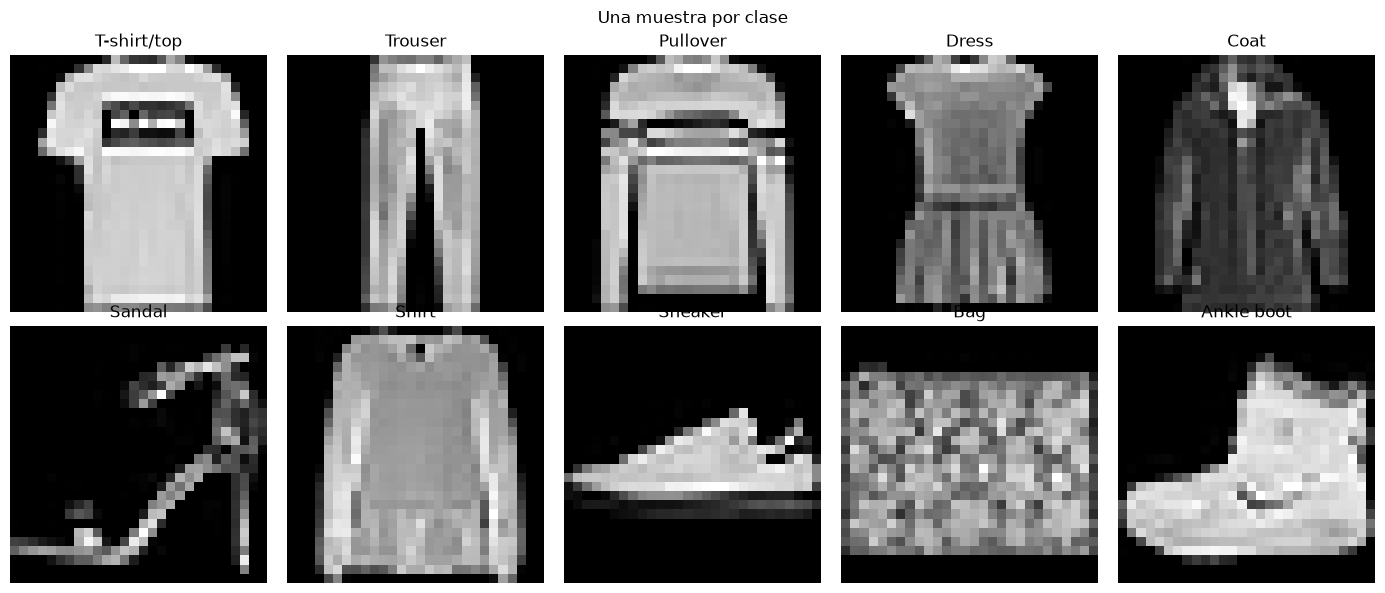

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
contador = {i: 0 for i in range(10)}
idx = 0

for imagen, etiqueta in train_dataset:
    if contador[etiqueta] == 0:
        ax = axes[etiqueta // 5, etiqueta % 5]
        ax.imshow(imagen.squeeze(), cmap="gray")
        ax.set_title(clases[etiqueta])
        ax.axis("off")
        contador[etiqueta] += 1
    if all(v > 0 for v in contador.values()):
        break

plt.suptitle("Una muestra por clase")
plt.tight_layout()
plt.show()

## Distribucion de clases

Verificamos que el dataset este balanceado. Un dataset balanceado
simplifica el entrenamiento y evita sesgos hacia clases mayoritarias.

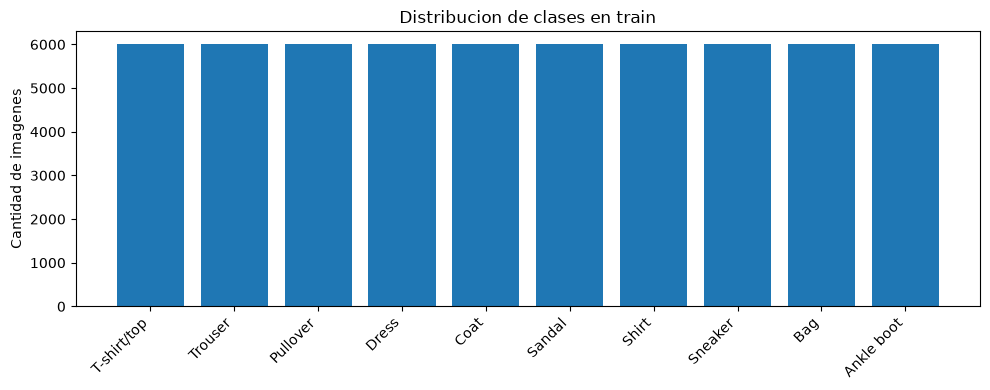

 T-shirt/top: 6000 imagenes
     Trouser: 6000 imagenes
    Pullover: 6000 imagenes
       Dress: 6000 imagenes
        Coat: 6000 imagenes
      Sandal: 6000 imagenes
       Shirt: 6000 imagenes
     Sneaker: 6000 imagenes
         Bag: 6000 imagenes
  Ankle boot: 6000 imagenes


In [6]:
etiquetas_train = [etiqueta for _, etiqueta in train_dataset]
conteo = np.bincount(etiquetas_train)

plt.figure(figsize=(10, 4))
plt.bar(clases, conteo)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Cantidad de imagenes")
plt.title("Distribucion de clases en train")
plt.tight_layout()
plt.show()

for i, c in enumerate(clases):
    print(f"{c:>12}: {conteo[i]} imagenes")

# 3. Division train / validation / test

Es buena practica separar un conjunto de validacion para monitorear
overfitting durante el entrenamiento y hacer early stopping. Usamos:

- Train: 54.000 imagenes para ajustar los pesos.
- Validation: 6.000 imagenes para monitorear y detener el entrenamiento.
- Test: 10.000 imagenes para la evaluacion final.

In [7]:
train_size = int(0.9 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42),
)

print("Train:", len(train_subset))
print("Validation:", len(val_subset))
print("Test:", len(test_dataset))

Train: 54000
Validation: 6000
Test: 10000


## DataLoaders

`DataLoader` se encarga de agrupar las muestras en batches, mezclarlas
y cargarlas en paralelo. Usamos:

- `batch_size=64`: un tamano comun y equilibrado.
- `shuffle=True` en train: mezcla las muestras en cada epoch.
- `shuffle=False` en val y test: el orden no importa.

In [8]:
batch_size = 64

train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

# Verificamos un batch
X_batch, y_batch = next(iter(train_loader))
print("Shape del batch de imagenes:", X_batch.shape)
print("Shape del batch de etiquetas:", y_batch.shape)

Shape del batch de imagenes: torch.Size([64, 1, 28, 28])
Shape del batch de etiquetas: torch.Size([64])


# 4. Definicion de la CNN

## Arquitectura

Disenamos una CNN simple pero efectiva para imagenes 28x28:

| Capa | Configuracion | Salida |
|---|---|---|
| Conv1 | Conv2d(1, 32, 3, padding=1) + ReLU | (32, 28, 28) |
| Pool1 | MaxPool2d(2) | (32, 14, 14) |
| Conv2 | Conv2d(32, 64, 3, padding=1) + ReLU | (64, 14, 14) |
| Pool2 | MaxPool2d(2) | (64, 7, 7) |
| Flatten | - | 64*7*7 = 3136 |
| FC1 | Linear(3136, 128) + ReLU | 128 |
| Dropout | Dropout(0.3) | 128 |
| FC2 | Linear(128, 10) | 10 |

La salida son 10 logits, uno por clase. No aplicamos Softmax porque
`CrossEntropyLoss` ya lo incluye internamente.

## Por que Dropout

Dropout apaga aleatoriamente un porcentaje de neuronas durante el
entrenamiento. Esto obliga a la red a no depender de neuronas
especificas y reduce el overfitting. Es especialmente util en las capas
fully connected, que concentran la mayor cantidad de parametros.

In [9]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(0.3)
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x


modelo = CNN().to(device)
print(modelo)

CNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


## Conteo de parametros

Es util saber cuantos parametros tiene el modelo, especialmente para
comparar arquitecturas o estimar el uso de memoria.

In [10]:
def contar_parametros(modelo):
    total = sum(p.numel() for p in modelo.parameters())
    entrenables = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    print(f"Parametros totales: {total:,}")
    print(f"Parametros entrenables: {entrenables:,}")

contar_parametros(modelo)

Parametros totales: 421,642
Parametros entrenables: 421,642


# 5. Entrenamiento

## Componentes del entrenamiento

- **Loss function**: `CrossEntropyLoss`. Combina `LogSoftmax` y
  `NLLLoss`. Espera logits crudos y etiquetas enteras.
- **Optimizer**: `Adam` con learning rate 0.001. Adaptativo y robusto.
- **Epochs**: 10. Con early stopping si validation loss no mejora.
- **Patience**: 3 epochs sin mejora antes de detener.

## Por que separar train y validation

El training loss siempre baja con mas epochs. El validation loss
refleja como generaliza el modelo. Cuando validation loss empieza a
subir mientras train loss sigue bajando, hay overfitting y es momento
de detener.

In [11]:
def entrenar(modelo, train_loader, val_loader, epochs=10, lr=0.001, patience=3):
    optimizer = torch.optim.Adam(modelo.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    historial_train = []
    historial_val = []
    mejor_val = float("inf")
    mejor_epoch = 0
    epochs_sin_mejora = 0

    for epoch in range(epochs):
        # Fase de entrenamiento
        modelo.train()
        perdida_total = 0.0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            logits = modelo(X_batch)
            loss = loss_fn(logits, y_batch)
            loss.backward()
            optimizer.step()
            perdida_total += loss.item() * X_batch.size(0)
        train_loss = perdida_total / len(train_loader.dataset)
        historial_train.append(train_loss)

        # Fase de validacion
        modelo.eval()
        perdida_val = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)
                logits = modelo(X_batch)
                loss = loss_fn(logits, y_batch)
                perdida_val += loss.item() * X_batch.size(0)
        val_loss = perdida_val / len(val_loader.dataset)
        historial_val.append(val_loss)

        print(f"Epoch {epoch+1:>2}/{epochs} | "
              f"train loss: {train_loss:.4f} | val loss: {val_loss:.4f}")

        # Early stopping
        if val_loss < mejor_val:
            mejor_val = val_loss
            mejor_epoch = epoch
            epochs_sin_mejora = 0
        else:
            epochs_sin_mejora += 1
            if epochs_sin_mejora >= patience:
                print(f"Early stopping en epoch {epoch+1}. "
                      f"Mejor epoch: {mejor_epoch+1} con val loss {mejor_val:.4f}")
                break

    return historial_train, historial_val, mejor_epoch


historial_train, historial_val, mejor_epoch = entrenar(
    modelo, train_loader, val_loader, epochs=10, lr=0.001, patience=3
)

Epoch  1/10 | train loss: 0.4684 | val loss: 0.3105
Epoch  2/10 | train loss: 0.3025 | val loss: 0.2707
Epoch  3/10 | train loss: 0.2535 | val loss: 0.2367
Epoch  4/10 | train loss: 0.2235 | val loss: 0.2300
Epoch  5/10 | train loss: 0.1995 | val loss: 0.2252
Epoch  6/10 | train loss: 0.1791 | val loss: 0.2265
Epoch  7/10 | train loss: 0.1642 | val loss: 0.2120
Epoch  8/10 | train loss: 0.1457 | val loss: 0.2242
Epoch  9/10 | train loss: 0.1337 | val loss: 0.2178
Epoch 10/10 | train loss: 0.1199 | val loss: 0.2338
Early stopping en epoch 10. Mejor epoch: 7 con val loss 0.2120


## Curvas de aprendizaje

Graficamos train loss y validation loss para visualizar el proceso.

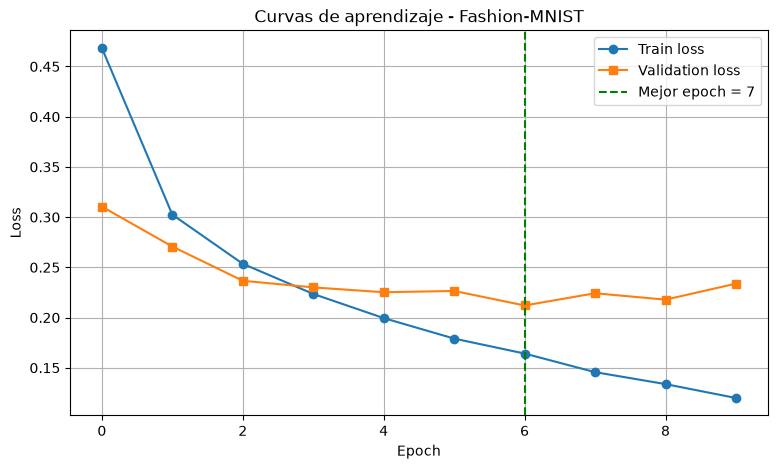

In [12]:
plt.figure(figsize=(9, 5))
plt.plot(historial_train, marker="o", label="Train loss")
plt.plot(historial_val, marker="s", label="Validation loss")
plt.axvline(mejor_epoch, color="green", linestyle="--",
            label=f"Mejor epoch = {mejor_epoch+1}")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Curvas de aprendizaje - Fashion-MNIST")
plt.legend()
plt.grid(True)
plt.show()

## Interpretacion

- Si ambas curvas bajan y se mantienen cercanas: el modelo esta
  aprendiendo bien.
- Si train baja pero validation sube: overfitting.
- Si ambas se estancan altas: underfitting. Habria que aumentar la
  capacidad del modelo o reducir la regularizacion.

# 6. Evaluacion en test

## Predicciones y metricas

Evaluamos el modelo final en el conjunto de test. Reportamos:

- Accuracy global.
- Precision, recall y F1 por clase.
- Matriz de confusion.

In [13]:
def obtener_predicciones(modelo, loader):
    modelo.eval()
    todas_pred = []
    todas_etiquetas = []
    todas_probs = []
    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            logits = modelo(X_batch)
            probs = F.softmax(logits, dim=1)
            pred = logits.argmax(dim=1)
            todas_pred.append(pred.cpu().numpy())
            todas_etiquetas.append(y_batch.numpy())
            todas_probs.append(probs.cpu().numpy())
    return (
        np.concatenate(todas_pred),
        np.concatenate(todas_etiquetas),
        np.concatenate(todas_probs),
    )


y_pred, y_true, y_probs = obtener_predicciones(modelo, test_loader)

accuracy = (y_pred == y_true).mean()
print(f"Accuracy en test: {accuracy:.4f}")
print()
print("Reporte por clase:")
print(classification_report(y_true, y_pred, target_names=clases, digits=4))

Accuracy en test: 0.9187

Reporte por clase:
              precision    recall  f1-score   support

 T-shirt/top     0.8523    0.8890    0.8703      1000
     Trouser     0.9940    0.9870    0.9905      1000
    Pullover     0.8745    0.8920    0.8832      1000
       Dress     0.9118    0.9300    0.9208      1000
        Coat     0.8602    0.8980    0.8787      1000
      Sandal     0.9754    0.9900    0.9826      1000
       Shirt     0.8027    0.7160    0.7569      1000
     Sneaker     0.9798    0.9230    0.9506      1000
         Bag     0.9949    0.9770    0.9859      1000
  Ankle boot     0.9390    0.9850    0.9614      1000

    accuracy                         0.9187     10000
   macro avg     0.9185    0.9187    0.9181     10000
weighted avg     0.9185    0.9187    0.9181     10000



## Matriz de confusion

La matriz de confusion muestra, para cada clase real, cuantas veces el
modelo predijo cada clase. Los valores en la diagonal son aciertos; los
de fuera, errores.

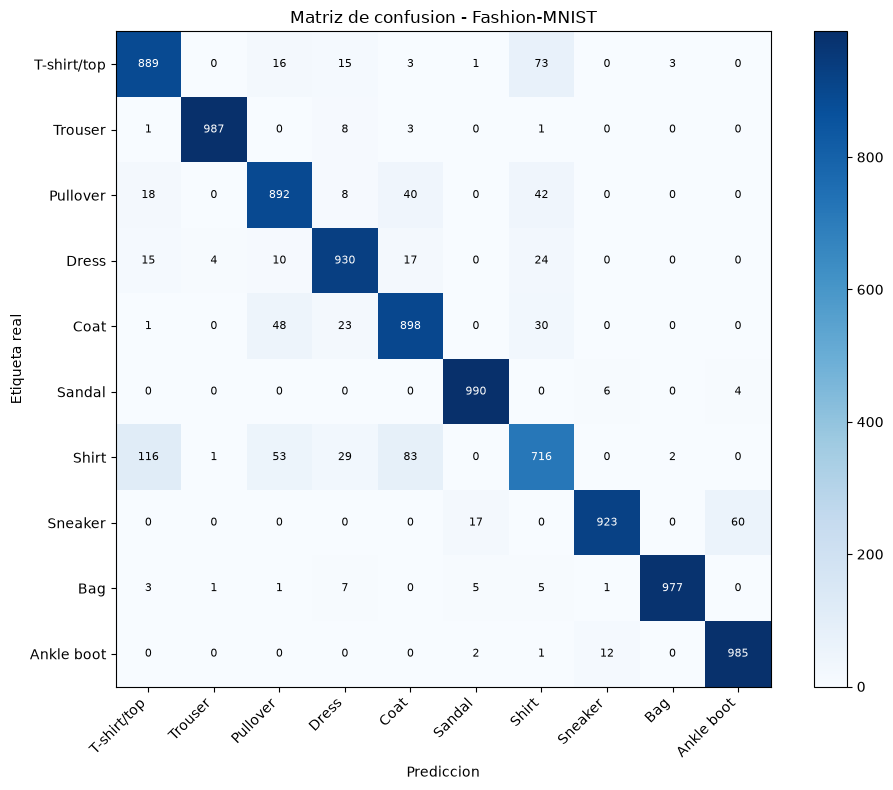

In [14]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks(range(10), clases, rotation=45, ha="right")
plt.yticks(range(10), clases)
plt.xlabel("Prediccion")
plt.ylabel("Etiqueta real")
plt.title("Matriz de confusion - Fashion-MNIST")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black",
                 fontsize=8)
plt.tight_layout()
plt.show()

## Observaciones tipicas

En Fashion-MNIST los errores mas frecuentes son entre:

- Shirt, Pullover, Coat y T-shirt/top: prendas superiores visualmente
  similares.
- Sneaker y Ankle boot: calzados parecidos.
- Sandal y Sneaker: dependiendo del angulo, pueden confundirse.

Estas confusiones son esperables incluso para humanos, dado el tamano
reducido de las imagenes.

# 7. Visualizacion de filtros

## Que aprenden los filtros

Los filtros de la primera capa convolucional aprenden detectores de
bordes y texturas. Visualizarlos ayuda a interpretar que aprendio la
red.

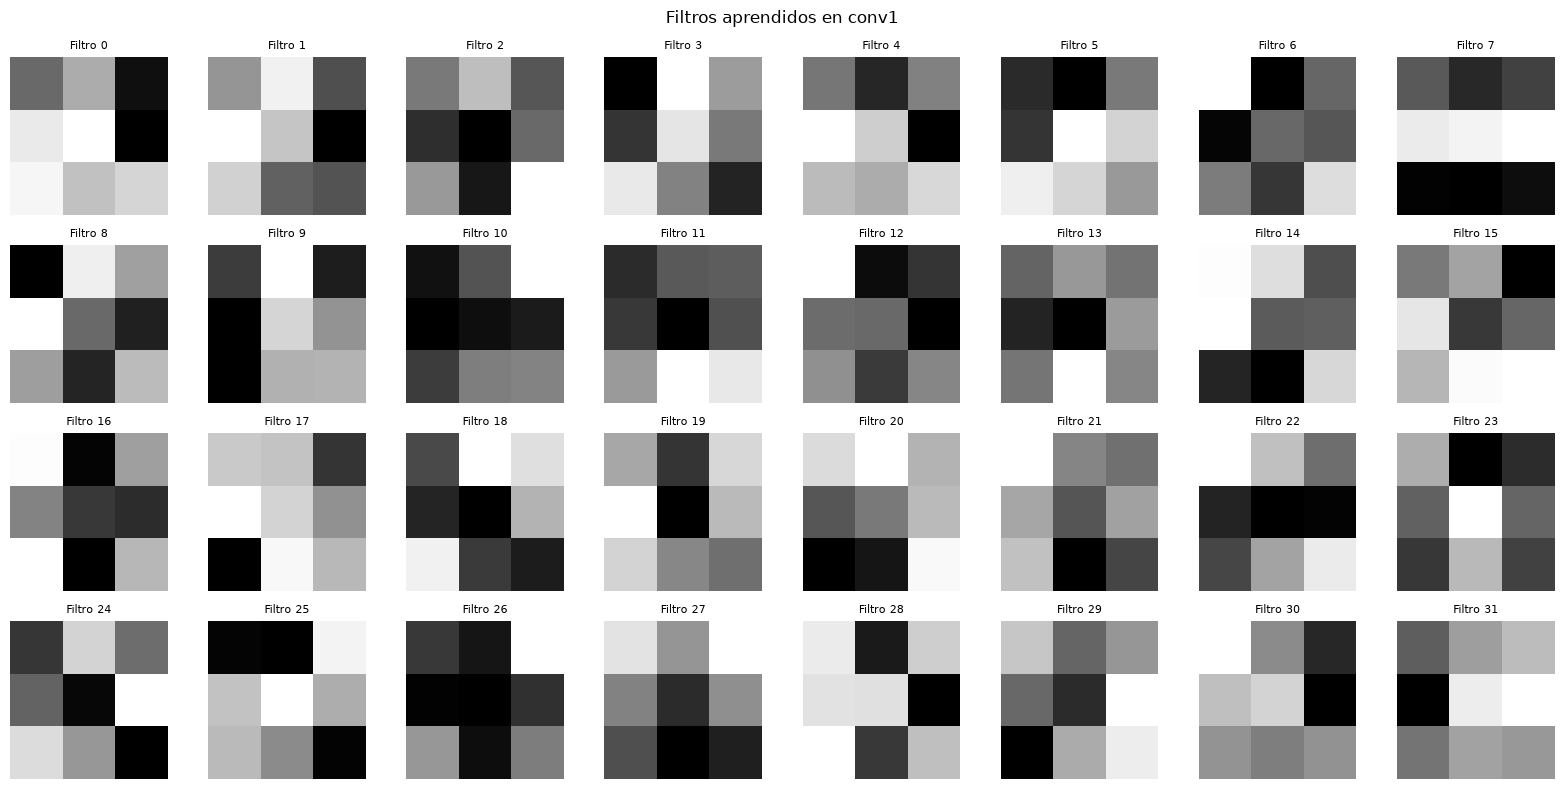

In [15]:
filtros = modelo.conv1.weight.detach().cpu()

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for i, ax in enumerate(axes.flat):
    if i < filtros.shape[0]:
        ax.imshow(filtros[i, 0], cmap="gray")
        ax.set_title(f"Filtro {i}", fontsize=8)
    ax.axis("off")
plt.suptitle("Filtros aprendidos en conv1")
plt.tight_layout()
plt.show()

# 8. Visualizacion de feature maps

Aplicamos la primera capa convolucional a una imagen y visualizamos las
activaciones. Cada canal muestra que patron detecto ese filtro.

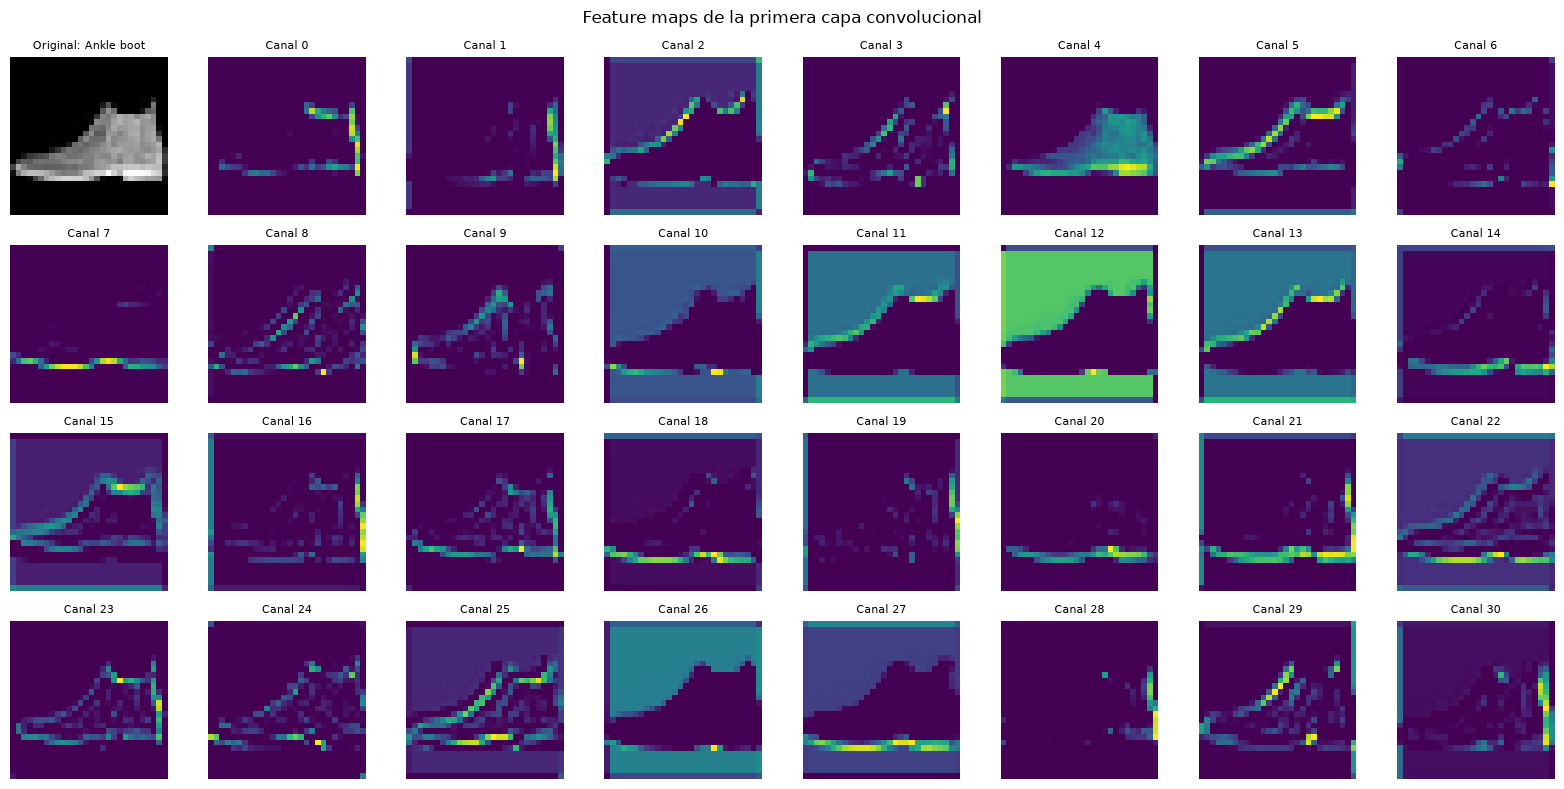

In [16]:
imagen, etiqueta = test_dataset[0]
imagen_tensor = imagen.unsqueeze(0).to(device)

with torch.no_grad():
    activaciones = F.relu(modelo.conv1(imagen_tensor)).cpu().squeeze(0)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
axes[0, 0].imshow(imagen.squeeze(), cmap="gray")
axes[0, 0].set_title(f"Original: {clases[etiqueta]}", fontsize=8)
axes[0, 0].axis("off")

for i, ax in enumerate(axes.flat[1:]):
    if i < activaciones.shape[0]:
        ax.imshow(activaciones[i], cmap="viridis")
        ax.set_title(f"Canal {i}", fontsize=8)
    ax.axis("off")
plt.suptitle("Feature maps de la primera capa convolucional")
plt.tight_layout()
plt.show()

# 9. Analisis de errores

Revisamos algunos ejemplos mal clasificados para entender donde falla el
modelo. Esta practica es clave para decidir si conviene recolectar mas
datos, cambiar la arquitectura o ajustar hiperparametros.

Total de errores en test: 813 de 10000



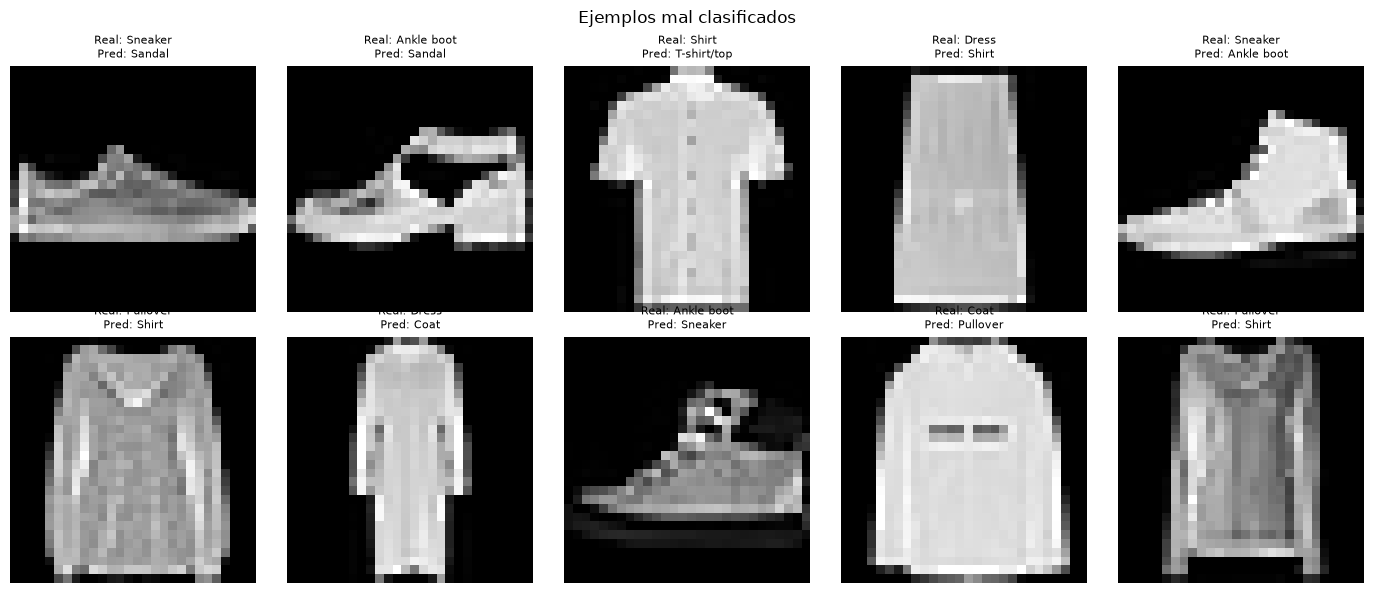

In [17]:
indices_error = np.where(y_pred != y_true)[0]
print(f"Total de errores en test: {len(indices_error)} de {len(y_true)}")
print()

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flat):
    if i < 10:
        idx = indices_error[i]
        img, _ = test_dataset[idx]
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(
            f"Real: {clases[y_true[idx]]}\nPred: {clases[y_pred[idx]]}",
            fontsize=8,
        )
    ax.axis("off")
plt.suptitle("Ejemplos mal clasificados")
plt.tight_layout()
plt.show()

## Preguntas para reflexionar

1. Los errores ocurren entre clases visualmente similares. Tiene sentido.
2. En algunos casos, la imagen es ambigua incluso para un humano.
3. Un accuracy cercano al 92 por ciento es tipico en Fashion-MNIST con
   CNN simples. Para superarlo se requieren arquitecturas mas profundas
   o tecnicas de data augmentation.

# 10. Resumen

## Lo que hicimos

- Cargamos y exploramos Fashion-MNIST con torchvision.
- Aplicamos transformaciones y normalizacion.
- Dividimos en train, validation y test.
- Definimos una CNN con dos capas convolucionales, pooling, dropout y
  dos capas fully connected.
- Entrenamos con Adam, CrossEntropyLoss y early stopping.
- Evaluamos con accuracy, precision, recall, F1 y matriz de confusion.
- Visualizamos filtros y feature maps.
- Analizamos errores del modelo.

## Resultados esperados

- Accuracy en test: aproximadamente 91 a 93 por ciento con esta
  arquitectura y 10 epochs.
- Las confusiones mas comunes ocurren entre prendas superiores
  (shirt, pullover, coat, t-shirt/top).

## Proximos pasos

- CIFAR-10: imagenes a color de 32x32 con 10 clases de objetos.
- ImageNette: subconjunto de ImageNet para transfer learning.
- Data augmentation mas agresivo y arquitecturas mas profundas para
  superar el 94 por ciento en Fashion-MNIST.

## Referencias

- Fashion-MNIST paper: https://arxiv.org/abs/1708.07747
- Documentacion de torchvision: https://pytorch.org/vision/stable/
- Documentacion de PyTorch: https://pytorch.org/docs/stable/